# HW5 이종석 · 21011615

매출 데이터 전처리를 재현하고 배송 기간, 만족도별 반품 비율, 카테고리별 매출을 분석합니다.

In [1]:
import pandas as pd

import matplotlib.pyplot as plt
import platform

fonts = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

## ① 읽고 날짜 세 칸을 날짜로

원본의 1,030행·14열을 읽고 주문일·배송일·도착일을 날짜형으로 변환합니다.
나이·만족도·도착일의 결측치는 임의로 대체하지 않습니다.

In [2]:
df = pd.read_csv("sales_data.csv")
dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])
print(df.shape)
df[["customer_age", "satisfaction", "delivery_date"]].isna().sum()

(1030, 14)


customer_age     51
satisfaction     30
delivery_date     5
dtype: int64

## ② 중복 행 제거

모든 열의 값이 같은 중복 행 26개만 제거하고 각 주문의 첫 행을 남깁니다.

In [3]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


## ③ 수량 복원

수업의 업무 규칙인 수량 100 초과에 해당하는 22행은 총액과 수량 × 단가가 맞지 않습니다.
총액 ÷ 단가가 정수로 복원되므로 수량만 고치고 총액·단가는 유지합니다.

In [4]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(), " 총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


## ④ 날짜 오류 표시와 저장

도착일이 배송일보다 빠른 행은 어느 날짜가 틀렸는지 확정할 수 없어 `date_error`로 표시만 합니다.
147행을 지우거나 날짜를 바꾸지 않고 1,004행·15열의 `sales_clean.csv`로 저장합니다.

In [5]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
print("날짜 오류 :", df["date_error"].sum())
df.to_csv("sales_clean.csv", index=False)
print(df.shape)
df["date_error"].value_counts()

날짜 오류 : 147
(1004, 15)


date_error
False    857
True     147
Name: count, dtype: int64

## ⑤ 배송 기간은 보통 며칠인가?

`date_error`가 아닌 행에서 도착일 − 배송일을 일수로 계산합니다.
먼저 전체 분포와 평균·중앙값을 보고 300일 초과 구간의 날짜를 확인합니다.

In [6]:
days = (df.loc[~df["date_error"], "delivery_date"]
        - df.loc[~df["date_error"], "shipping_date"]).dt.days
print("날짜 오류 제외 :", (~df["date_error"]).sum(), " 도착일 결측 :", days.isna().sum())
days = days.dropna()
print("유효 건수 :", days.count(), " 평균 :", round(days.mean(), 2), " 중앙값 :", days.median())
long_days = days[days > 300]
print("300일 초과 :", long_days.count(), " 최소 :", long_days.min(), " 최대 :", long_days.max())
df.loc[long_days.index, dates].head(8)

날짜 오류 제외 : 857  도착일 결측 : 5
유효 건수 : 852  평균 : 22.05  중앙값 : 2.0
300일 초과 : 47  최소 : 364.0  최대 : 370.0


,order_date,shipping_date,delivery_date
11,2023-01-12,2023-01-15,2024-01-15
20,2023-01-21,2023-01-23,2024-01-27
29,2023-01-30,2023-02-03,2024-02-03
41,2023-02-11,2023-02-14,2024-02-17
68,2023-03-10,2023-03-14,2024-03-12
99,2023-04-10,2023-04-11,2024-04-12
110,2023-04-21,2023-04-25,2024-04-24
131,2023-05-12,2023-05-13,2024-05-16


0~5일과 364~370일 사이에 값이 없는 큰 간격이 있습니다. 300일 초과 47건은 별도 장기 구간으로 분리합니다.
연도 입력 오류 가능성은 있지만 사실로 확정할 근거가 없어 날짜를 1년 줄여 고치지 않습니다. 일반 배송 기간을 요약할 때만 제외하고 `df`와 단계 ④의 CSV는 그대로 유지합니다.

전체 : 852  평균 : 22.05  중앙값 : 2.0
장기 구간 제외 : 805  평균 : 1.93  중앙값 : 2.0


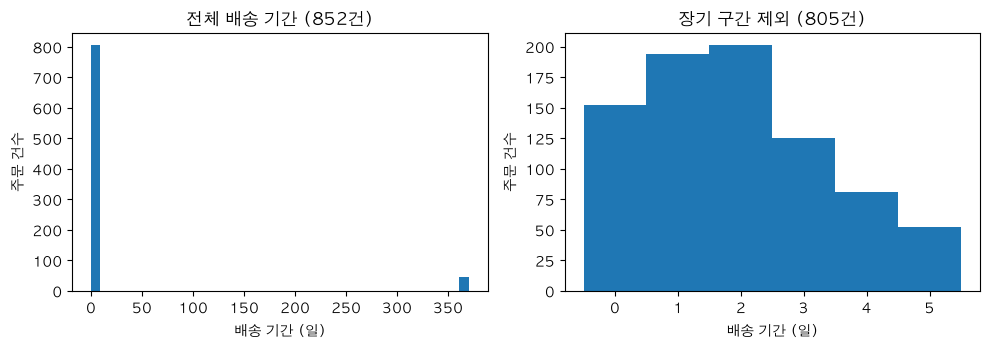

In [7]:
typical_days = days[days <= 300]
print("전체 :", days.count(), " 평균 :", round(days.mean(), 2), " 중앙값 :", days.median())
print("장기 구간 제외 :", typical_days.count(), " 평균 :", round(typical_days.mean(), 2),
      " 중앙값 :", typical_days.median())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
days.plot.hist(bins=40, ax=ax[0], title="전체 배송 기간 (852건)")
typical_days.plot.hist(bins=6, range=(-0.5, 5.5), ax=ax[1], title="장기 구간 제외 (805건)")
ax[0].set_xlabel("배송 기간 (일)")
ax[1].set_xlabel("배송 기간 (일)")
ax[0].set_ylabel("주문 건수")
ax[1].set_ylabel("주문 건수")
ax[1].set_xticks(range(6))
plt.tight_layout()
plt.show()

**답:** 유효 852건의 평균은 22.05일, 중앙값은 2일이며, 364~370일인 47건이 평균을 끌어올립니다.  
일반 구간과 크게 떨어진 47건은 날짜를 고치지 않고 기간 요약에서만 제외했으며, 나머지 805건의 평균은 1.93일·중앙값은 2일이므로 보통 약 2일입니다.

## ⑥ 만족도가 낮을수록 반품이 많은가?

상태가 `반품`이면 True인 값을 만족도별로 묶어 평균을 내고 백분율로 표시합니다.
만족도 결측 30건은 이 분석에서만 빠지며, 비율의 분모는 각 만족도에 속한 전체 주문 수입니다.

만족도 유효 : 974  결측 : 30


,전체 주문 수,반품 수,반품 비율 (%)
satisfaction,,,
1,224,17,7.59
2,184,22,11.96
3,192,15,7.81
4,172,15,8.72
5,202,14,6.93


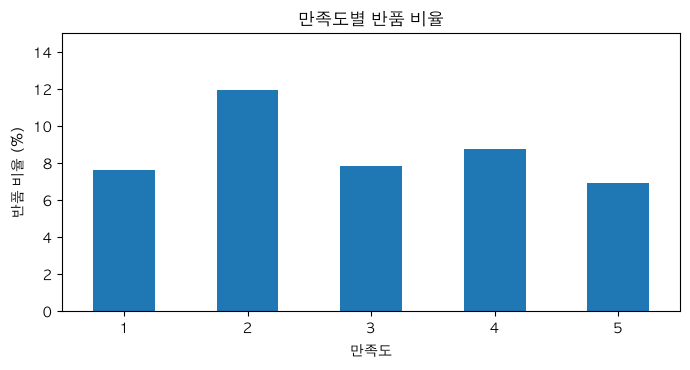

In [8]:
returned = df["status"] == "반품"
return_rate = returned.groupby(df["satisfaction"]).mean() * 100
return_summary = pd.DataFrame({
    "전체 주문 수": returned.groupby(df["satisfaction"]).count(),
    "반품 수": returned.groupby(df["satisfaction"]).sum(),
    "반품 비율 (%)": return_rate
})
return_summary.index = return_summary.index.astype(int)
print("만족도 유효 :", df["satisfaction"].count(), " 결측 :", df["satisfaction"].isna().sum())
display(return_summary.round(2))

ax = return_rate.plot.bar(figsize=(7, 3.8), rot=0, title="만족도별 반품 비율")
ax.set_xticklabels([1, 2, 3, 4, 5])
ax.set_xlabel("만족도")
ax.set_ylabel("반품 비율 (%)")
ax.set_ylim(0, 15)
plt.tight_layout()
plt.show()

**답:** 아니다. 만족도 1~5점의 반품 비율은 각각 7.59%, 11.96%, 7.81%, 8.72%, 6.93%로 만족도가 낮을수록 일관되게 증가하지 않습니다.  
2점이 22/184건(11.96%)으로 가장 높고 1점은 17/224건(7.59%)이므로, 이 집계만으로 낮은 만족도가 반품 증가의 원인이라고 단정할 수 없습니다.

## ⑦ 카테고리 매출 1위의 차이는 건수·단가·수량 중 어디에 있는가?

카테고리별 주문 건수·총매출·평균 단가·평균 수량을 `groupby().agg()`로 비교합니다.
총매출은 수업과 같이 모든 상태의 주문에 기록된 `total_sales` 합계이며, 순매출로 해석하지 않습니다.

In [9]:
by_cat = df.groupby("category").agg(
    주문건수=("total_sales", "size"),
    총매출=("total_sales", "sum"),
    평균단가=("unit_price", "mean"),
    평균수량=("quantity", "mean")
).sort_values("총매출", ascending=False)
by_cat["총매출(억원)"] = by_cat["총매출"] / 1e8
by_cat.round(2)

,주문건수,총매출,평균단가,평균수량,총매출(억원)
category,,,,,
가구,213,2.843337e+09,257322.91,51.04,28.43
식품,210,2.513274e+09,255232.93,47.31,25.13
전자제품,207,2.471628e+09,249651.61,47.96,24.72
도서,204,2.453240e+09,238500.64,49.50,24.53
의류,170,2.181904e+09,249447.16,51.61,21.82


**답:** 매출 1위는 가구(28.43억 원)이며 주문 213건·평균 단가 257,322.91원으로 두 항목 모두 1위입니다. 2위 식품은 210건·255,232.93원·평균 수량 47.31개입니다.  
가구의 평균 수량은 51.04개로 식품보다 많지만 의류 51.61개보다는 적습니다. 가구는 건수·단가가 모두 높고 수량도 높은 편이나, 합계 비교만으로 한 요소가 유일한 원인이라고 단정하지 않습니다.